# CRAG

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 자료의 여덟 질문으로 첫 자리 거리가 어느 범위인지 봅니다.
3. 그 눈금을 보고 거리 기준값과 반복 상한을 정합니다.
4. 일상 말로 짧게 적은 원 질문을 한 번만 검색합니다.
5. 첫 자리 거리가 기준값보다 크면 보정 질문을 받아 다시 검색합니다.
6. 거리 기준값 하나만 늘려 같은 결과를 다시 판정합니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 열두 번이고 임베딩 열한 번과 답 모델 한 번입니다.
답 모델은 다시 검색하는 갈래에서만 한 번 부르고 예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 9절까지 읽습니다.
Ch 12 검색 부품을 준비하고 거리 눈금을 보고 기준값을 정하는 자리입니다.
10절부터 12절까지는 짧게 적은 질문을 검색하고 한 번 더 검색하는 자리입니다.
13절부터 15절까지는 기준값을 늘려 보고 세 실행을 표로 보는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

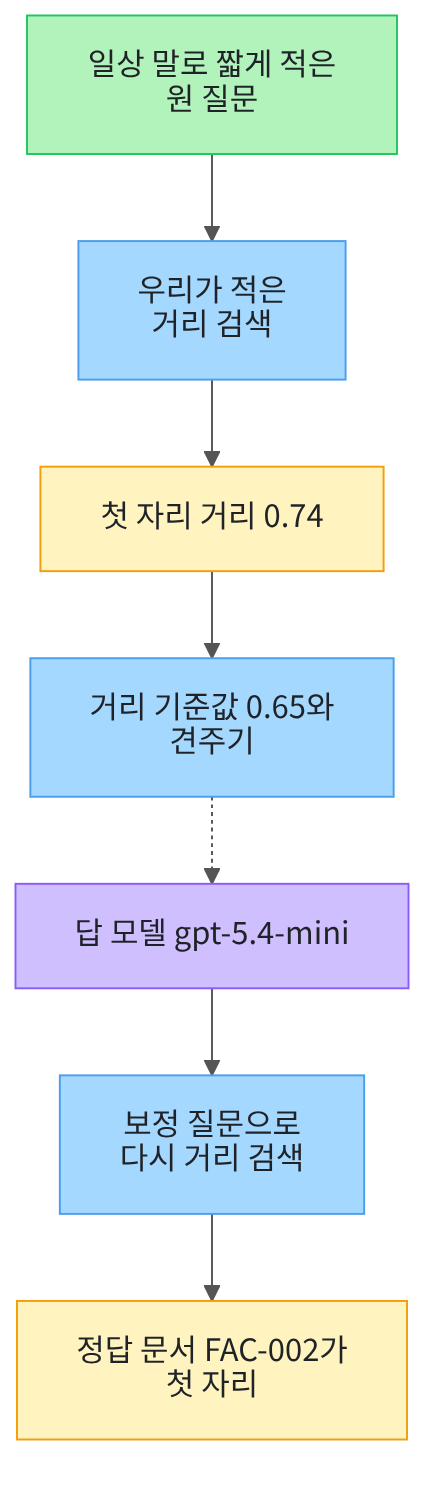

위에서 아래로 읽습니다.
맨 위 초록 상자가 사람이 적은 질문입니다.
파란 상자 셋이 우리가 적은 처리와 판정 규칙이고 보라 상자가 모델입니다.
노란 상자 둘이 출력으로 확인한 값입니다.
점선은 기준값에 따라 갈라지는 자리입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 다섯 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 Ch 12 01절 `rank_by_distance()`와 05절 `print_ranked()`를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`와 02절 `split_lines()`도 가져옵니다.
거리 순위 함수는 질문 벡터와 문서 벡터 목록과 문서 ID 목록과 개수를 받습니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# Ch 12 01·05절·Ch 11 01절 함수와 02절 줄 나누기 함수를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, print_ranked, rank_by_distance, split_lines
from rag_tools import unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 05절에서 쓴 것과 같습니다.
도구 파일에서 가져온 함수 다섯 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~05절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~05절에서 쓴 방법과 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절은 그 여덟 질문으로 거리 눈금을 보고 검색에는 다른 물음을 씁니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12와 01~05절에서 정한 값 둘을 그대로 다시 적습니다.
이 절이 새로 정할 값 둘은 눈금을 본 뒤 8절에서 적습니다.

In [7]:
# Ch 12에서 쓴 값 둘을 그대로 다시 정합니다
top_three = 3
top_all = 12
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12


**결과 읽기** — 출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 정답 문서의 자리를 끝까지 세려고 둔 값입니다.

05절은 이 자리에 가상 문서의 문장 수도 함께 적었습니다.
이 절이 새로 정할 값은 거리 기준값과 반복 상한 둘입니다.

## 5. 앞 절 부품 준비

다음 셀은 01~05절과 같은 방법으로 문서 열두 건의 제목과 본문을 이어 붙입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
함수는 준비 셀에서 도구 파일로 가져왔습니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12와 같은 제목 + 본문 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


준비 셀 하나를 지났습니다.
02·03절이 쓴 순위 합치기 함수는 04·05절에 이어 이 절에서도 가져오지 않았습니다.
이 절도 목록 여러 개를 하나로 합치지 않기 때문입니다.
02절 검색 묶음 함수 `search_ids`도 가져오지 않았습니다.
그 함수는 문서 ID만 내주어 거리 값을 볼 수 없기 때문입니다.

## 6. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [9]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 05절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 7. 거리까지 함께 보는 검색 함수

02절 `search_ids`는 문서 ID 목록만 내주었습니다.
이 절은 첫 자리 거리를 봐야 하므로 순위 목록을 그대로 내주는 함수를 만듭니다.
목록 한 줄에는 문서 ID와 거리가 함께 담깁니다.

In [10]:
# 질문 하나를 벡터로 바꿔 문서 열두 건의 거리 순위 목록을 만듭니다
def search_hits(question):
    question_vector = embedding_model.embed_query(question)
    hit_list = rank_by_distance(question_vector, doc_vectors, doc_ids, top_all)
    return hit_list

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `search_hits`는 질문 하나를 벡터로 바꾸고 거리 순위 목록을 만듭니다.
안에서 부르는 두 함수는 05절까지 쓰던 것과 같습니다.
문서 ID만 필요할 때는 `unique_doc_ids`를 뒤에 한 번 더 부릅니다.

## 8. 거리 눈금을 보고 기준값 정하기

기준값을 먼저 정해 놓고 결과를 재면 값을 마음대로 맞출 수 있습니다.
그래서 자료의 여덟 질문으로 첫 자리 거리가 어느 범위인지 먼저 봅니다.

In [11]:
# 자료의 여덟 질문으로 첫 자리 거리가 어느 범위에 있는지 먼저 봅니다(임베딩 요청 8번)
scale_rows = []
for query in queries:
    query_hits = search_hits(query["question"])
    scale_rows.append({"질문 번호": query["qid"], "첫 자리 거리": query_hits[0]["거리"]})
print("질문 번호 | 첫 자리 거리")
for row in scale_rows:
    print(row["질문 번호"], "|", row["첫 자리 거리"])

질문 번호 | 첫 자리 거리
C01 | 0.43
C02 | 0.56
C03 | 0.35
C04 | 0.37
C05 | 0.6
C06 | 0.51
C07 | 0.28
C08 | 0.53


**결과 읽기** — 라벨 줄 `질문 번호 | 첫 자리 거리` 아래에 여덟 줄이 나옵니다.
가장 작은 값은 `C07`의 줄이고 가장 큰 값은 `C05`의 줄입니다.
여덟 줄 모두 자료가 쓰는 낱말과 겹치도록 적은 질문입니다.

여덟 값은 0.28에서 0.6 사이에 있습니다.
이 값들은 호출마다 아주 조금씩 달라질 수 있습니다.

다음 셀은 그 눈금보다 조금 큰 값을 기준값으로 적습니다.

In [12]:
# 여덟 질문의 첫 자리 거리보다 조금 큰 값을 거리 기준값으로 정합니다
distance_limit = 0.65
retry_limit = 1
print("거리 기준값:", distance_limit)
print("다시 검색할 수 있는 횟수 상한:", retry_limit)

거리 기준값: 0.65
다시 검색할 수 있는 횟수 상한: 1


**결과 읽기** — 출력 줄 `거리 기준값: 0.65`가 이 절의 갈래를 가르는 값입니다.
출력 줄 `다시 검색할 수 있는 횟수 상한: 1`은 다시 검색을 한 번까지만 한다는 뜻입니다.
두 값 모두 이름 있는 변수로 적어 두어 식 안에 숫자를 바로 쓰지 않습니다.

기준값 `0.65`는 이 자료에서 고른 값이고 정답 확률이 아닙니다.
자료나 임베딩 모델이 바뀌면 다시 재고 다시 정해야 합니다.

## 9. 다시 검색할지 정하는 규칙

이 챕터는 코사인 거리를 씁니다.
거리는 작을수록 가깝고 클수록 멉니다.
그래서 첫 자리 거리가 기준값보다 크면 다시 검색합니다.

In [13]:
# 거리는 작을수록 가까우므로 기준값보다 크면 다시 검색하기로 정합니다
def needs_retry(top_distance, limit):
    if top_distance > limit:
        return True
    return False

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `needs_retry`는 첫 자리 거리와 기준값 둘을 받습니다.
거리가 기준값보다 크면 참이고 아니면 거짓입니다.
부등호 방향을 뒤집으면 가까운 결과를 다시 검색하게 되니 조심합니다.

## 10. 짧게 적은 원 질문

자료의 문서는 안내문 문장으로 적혀 있습니다.
사람이 묻는 말은 그보다 짧고 쓰는 낱말도 다릅니다.
그런 질문을 하나 적고 판단에 쓸 정답 문서도 함께 정합니다.

In [14]:
# 일상에서 말하듯 짧게 적은 원 질문과 그 질문의 정답 문서를 정합니다
base_question = "알록달록하게 뽑으면 더 비싼가요?"
gold_doc_id = "FAC-002"
gold_title = ""
for doc in docs:
    if doc["doc_id"] == gold_doc_id:
        gold_title = doc["title"]
print("원 질문:", base_question)
print("이 질문의 정답 문서 ID:", gold_doc_id)
print("그 문서의 제목:", gold_title)

원 질문: 알록달록하게 뽑으면 더 비싼가요?
이 질문의 정답 문서 ID: FAC-002
그 문서의 제목: 프린터 이용


**결과 읽기** — 출력 줄 `원 질문` 뒤에 색을 넣어 인쇄하는 값을 묻는 짧은 물음이 있습니다.
출력 줄 `이 질문의 정답 문서 ID: FAC-002`는 인쇄 요금을 적은 문서입니다.
출력 줄 `그 문서의 제목: 프린터 이용`으로 제목을 확인했습니다.

실행 전에 예상해 봅니다.
질문에 인쇄라는 말도 요금이라는 말도 없으니 다른 문서가 먼저 걸릴 것입니다.

In [15]:
# 원 질문을 한 번만 검색해 순위 표와 첫 자리 거리와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
base_hits = search_hits(base_question)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
base_distance = base_hits[0]["거리"]
print_ranked(base_hits[:top_three], "거리")
print("첫 자리 거리:", base_distance)
print("원 질문으로 검색했을 때 정답 문서의 자리:", base_place)

순위 | 문서 ID | 거리
1 | ACC-001 | 0.74
2 | LIB-003 | 0.77
3 | FAC-002 | 0.79
첫 자리 거리: 0.74
원 질문으로 검색했을 때 정답 문서의 자리: 3


**결과 읽기** — 출력 줄 `첫 자리 거리: 0.74`가 이 절이 볼 값입니다.
순위 표의 첫 자리는 `ACC-001`이고 이 물음의 정답 문서가 아닙니다.
출력 줄 `원 질문으로 검색했을 때 정답 문서의 자리: 3`으로 정답 문서는 셋째였습니다.

첫 자리에 선 문서는 비밀번호 재설정을 적은 문서입니다.
짧은 물음에 자료가 쓰는 낱말이 거의 들어 있지 않습니다.

다음 셀은 그 거리를 기준값과 견줍니다.

In [16]:
# 첫 자리 거리를 기준값과 견주어 다시 검색할지 정합니다
base_retry = needs_retry(base_distance, distance_limit)
print("첫 자리 거리:", base_distance)
print("거리 기준값:", distance_limit)
print("다시 검색하기로 했는가:", base_retry)

첫 자리 거리: 0.74
거리 기준값: 0.65
다시 검색하기로 했는가: True


**결과 읽기** — 출력 줄 `첫 자리 거리: 0.74`와 출력 줄 `거리 기준값: 0.65`를 나란히 봅니다.
출력 줄 `다시 검색하기로 했는가: True`로 거리가 기준값보다 컸습니다.
여기까지가 검색 뒤에 코드가 내린 판정입니다.

## 11. 보정 질문 받기

다시 검색하려면 넣을 글이 있어야 합니다.
같은 질문을 그대로 넣으면 결과도 같습니다.
그래서 모델에게 자료 말투에 가까운 물음으로 다시 적어 달라고 합니다.

In [17]:
# 머리글 네 줄과 원 질문을 한 글로 이어 붙입니다
def build_fix_prompt(question):
    fix_head = "아래 질문을 도서관 안내문에서 찾기 좋은 말로 다시 적으세요.\n"
    fix_head = fix_head + "줄임말과 일상 말을 안내문에서 쓰는 말로 바꾸세요.\n"
    fix_head = fix_head + "새 조건을 보태지 말고 묻는 내용은 그대로 두세요.\n"
    fix_head = fix_head + "물음 한 문장만 적고 번호나 따옴표를 붙이지 마세요.\n\n"
    prompt_text = fix_head + "질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_fix_prompt`는 머리글 네 줄을 이어 붙인 뒤 원 질문을 답니다.
새 조건을 보태지 말라는 줄을 둔 까닭은 묻는 내용이 바뀌면 안 되기 때문입니다.
한 문장만 적으라는 줄은 뒤에서 맨 앞 줄만 쓰기 때문입니다.

다음 셀은 판정과 모델 호출을 한 함수로 묶습니다.

In [18]:
# 다시 검색하기로 한 갈래에서만 모델을 불러 보정 질문을 받습니다
def correct_once(question, top_distance, limit):
    row = {"보정 질문": question, "다시 검색한 횟수": 0}
    if needs_retry(top_distance, limit):
        fix_prompt = build_fix_prompt(question)
        fix_reply = model.invoke(fix_prompt)
        fix_lines = split_lines(fix_reply.text.strip())
        row["보정 질문"] = fix_lines[0]
        row["다시 검색한 횟수"] = 1
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `correct_once`는 기록 한 줄을 만들어 보정 질문과 다시 검색한 횟수를 담습니다.
다시 검색하지 않기로 하면 원 질문과 횟수 영을 그대로 담습니다.
다시 검색하기로 할 때만 모델을 부르므로 요청은 그 갈래에서만 늘어납니다.

다음 셀은 원 질문을 그 함수에 넣습니다.

In [19]:
# 원 질문과 첫 자리 거리를 그 규칙에 넣어 보정 질문을 받습니다(모델 요청 1번)
base_row = correct_once(base_question, base_distance, distance_limit)
fix_question = base_row["보정 질문"]
base_retry_count = base_row["다시 검색한 횟수"]
print("다시 검색한 횟수:", base_retry_count)
print("검색에 넣을 보정 질문:")
print(fix_question)

다시 검색한 횟수: 1
검색에 넣을 보정 질문:
컬러로 출력하면 비용이 더 많이 드나요?


**결과 읽기** — 출력 줄 `다시 검색한 횟수: 1`로 이번에는 모델을 한 번 불렀습니다.
라벨 줄 `검색에 넣을 보정 질문:` 아래에 다시 적은 물음 한 줄이 있습니다.

그 문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.
묻는 내용은 그대로이고 쓰는 낱말만 자료 말투에 가까워집니다.

## 12. 보정 질문으로 다시 검색하기

이번에는 방금 받은 물음을 검색에 넣습니다.
같은 문서 열두 건에서 같은 방법으로 순위를 만듭니다.

In [20]:
# 보정 질문으로 다시 검색해 순위 표와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
fix_hits = search_hits(fix_question)
fix_ids = unique_doc_ids(fix_hits)
fix_place = find_gold_rank(fix_ids, [gold_doc_id])
fix_distance = fix_hits[0]["거리"]
print_ranked(fix_hits[:top_three], "거리")
print("보정 검색의 첫 자리 거리:", fix_distance)
print("보정 질문으로 검색했을 때 정답 문서의 자리:", fix_place)

순위 | 문서 ID | 거리
1 | FAC-002 | 0.4
2 | LIB-004 | 0.71
3 | ACC-004 | 0.81
보정 검색의 첫 자리 거리: 0.4
보정 질문으로 검색했을 때 정답 문서의 자리: 1


**결과 읽기** — 순위 표의 첫 자리는 `FAC-002`입니다.
출력 줄 `보정 질문으로 검색했을 때 정답 문서의 자리: 1`로 정답 문서가 맨 앞에 왔습니다.
같은 문서가 원 질문에서는 셋째 자리였습니다.

출력 줄 `보정 검색의 첫 자리 거리` 뒤의 값은 모델이 쓴 문장에 따라 달라집니다.
문장이 바뀌면 검색에 넣는 글이 바뀌기 때문입니다.
이번 실행에서 그 값은 기준값보다 작았습니다.
한 번 더 검색해도 정답 문서가 늘 앞으로 온다는 뜻은 아닙니다.

## 13. 값 바꿔 보기 · 거리 기준값 늘리기

바꿀 값은 거리 기준값 하나입니다.
질문도 첫 검색 결과도 그대로 두고 기준값만 늘립니다.
실행 전에 예상해 봅니다.
같은 거리 `0.74`가 늘린 기준값보다 작으면 다시 검색하지 않을 것입니다.

In [21]:
# 바꿀 값은 거리 기준값 하나이고 질문과 첫 검색 결과는 그대로 둡니다
loose_limit = 0.8
loose_row = correct_once(base_question, base_distance, loose_limit)
loose_retry_count = loose_row["다시 검색한 횟수"]
print("바꾼 거리 기준값:", loose_limit)
print("바꾼 기준값에서 다시 검색한 횟수:", loose_retry_count)
print("그대로 둔 첫 자리 문서:", base_ids[0])
print("그대로 둔 정답 문서의 자리:", base_place)

바꾼 거리 기준값: 0.8
바꾼 기준값에서 다시 검색한 횟수: 0
그대로 둔 첫 자리 문서: ACC-001
그대로 둔 정답 문서의 자리: 3


**결과 읽기** — 출력 줄 `바꾼 거리 기준값: 0.8`이 이번에 바꾼 값입니다.
출력 줄 `바꾼 기준값에서 다시 검색한 횟수: 0`으로 모델을 부르지 않았습니다.
출력 줄 `그대로 둔 정답 문서의 자리: 3`으로 첫 검색 결과를 그대로 뒀습니다.

같은 검색 결과가 기준값 하나로 다른 갈래를 갔습니다.
기준값을 크게 잡으면 먼 결과도 그대로 쓰게 됩니다.

## 14. 반복 상한 확인

다시 검색할 때마다 요청이 늘어납니다.
상한을 값으로 적어 두고 실제 횟수와 나란히 봅니다.

In [22]:
# 갈래마다 다시 검색한 횟수가 상한을 넘지 않았는지 확인합니다
print("다시 검색할 수 있는 횟수 상한:", retry_limit)
print("처음 기준값에서 다시 검색한 횟수:", base_retry_count)
print("늘린 기준값에서 다시 검색한 횟수:", loose_retry_count)
assert base_retry_count <= retry_limit, "처음 기준값 갈래에서 상한을 넘었습니다."
assert loose_retry_count <= retry_limit, "늘린 기준값 갈래에서 상한을 넘었습니다."

다시 검색할 수 있는 횟수 상한: 1
처음 기준값에서 다시 검색한 횟수: 1
늘린 기준값에서 다시 검색한 횟수: 0


**결과 읽기** — 출력 줄 `다시 검색할 수 있는 횟수 상한: 1`이 코드에 적어 둔 값입니다.
출력 줄 `처음 기준값에서 다시 검색한 횟수: 1`은 상한과 같습니다.
출력 줄 `늘린 기준값에서 다시 검색한 횟수: 0`은 상한보다 작습니다.

`assert` 두 줄은 이 세 값만 봅니다.
모델이 쓴 문장에는 `assert`를 걸지 않았습니다.

## 15. 세 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01·02·04·05절에서 쓴 기록 한 줄과 같은 모양입니다.
칸 둘을 더했습니다.
이 절이 견주는 값에 첫 자리 거리와 다시 검색한 횟수가 있기 때문입니다.

In [23]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, search_text, found_ids, place, top_distance, retry_count):
    row = {"실행": run_name}
    row["검색에 넣은 글"] = search_text
    row["첫 자리 문서"] = found_ids[0]
    row["정답 자리"] = place
    row["첫 자리 거리"] = top_distance
    row["다시 검색한 횟수"] = retry_count
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 검색에 넣은 글과 첫 자리 문서와 정답 자리 넷입니다.
여기에 첫 자리 거리와 다시 검색한 횟수를 더해 여섯 칸입니다.

다음 셀은 세 실행의 기록을 표로 출력합니다.

In [24]:
# 세 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("원 질문 한 번 검색", base_question, base_ids, base_place, base_distance, 0))
run_rows.append(run_row("보정 질문으로 다시 검색", fix_question, fix_ids, fix_place, fix_distance, base_retry_count))
run_rows.append(run_row("기준값을 늘린 실행", base_question, base_ids, base_place, base_distance, loose_retry_count))
print("실행 | 첫 자리 문서 | 정답 자리 | 첫 자리 거리 | 다시 검색한 횟수")
for row in run_rows:
    print(row["실행"], "|", row["첫 자리 문서"], "|", row["정답 자리"], "|", row["첫 자리 거리"], "|", row["다시 검색한 횟수"])
    print("  검색에 넣은 글:", row["검색에 넣은 글"])

실행 | 첫 자리 문서 | 정답 자리 | 첫 자리 거리 | 다시 검색한 횟수
원 질문 한 번 검색 | ACC-001 | 3 | 0.74 | 0
  검색에 넣은 글: 알록달록하게 뽑으면 더 비싼가요?
보정 질문으로 다시 검색 | FAC-002 | 1 | 0.4 | 1
  검색에 넣은 글: 컬러로 출력하면 비용이 더 많이 드나요?
기준값을 늘린 실행 | ACC-001 | 3 | 0.74 | 0
  검색에 넣은 글: 알록달록하게 뽑으면 더 비싼가요?


**결과 읽기** — 라벨 줄 아래 첫 줄은 `원 질문 한 번 검색 | ACC-001 | 3 | 0.74 | 0`입니다.
셋째 줄은 `기준값을 늘린 실행 | ACC-001 | 3 | 0.74 | 0`으로 첫 줄과 같습니다.
기준값만 늘리면 검색 결과가 그대로라는 것이 두 줄로 보입니다.

둘째 줄의 첫 자리 문서는 `FAC-002`이고 정답 자리는 하나입니다.
그 줄의 첫 자리 거리는 모델이 쓴 문장에 따라 달라집니다.

## 정리

1. 자료의 여덟 질문으로 첫 자리 거리의 눈금을 보고 기준값을 정했습니다.
2. 짧게 적은 원 질문의 첫 자리 거리가 기준값보다 커서 한 번 더 검색했습니다.
3. 보정 검색에서 정답 문서가 셋째 자리에서 첫 자리로 왔습니다.
4. 기준값만 늘리자 같은 결과에서 다시 검색하지 않았습니다.

07절에서는 답을 만든 뒤 그 답이 근거와 맞는지 확인합니다.
이 절은 검색 뒤에 다시 검색할지 정했고 07절은 답을 만든 뒤 고칠지 정합니다.